#### AWS SBH AIML Pre-requisite tasks

### TASK 1: CLEANING AND EXPLORATION

In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [32]:
df =pd.read_csv("/content/house_prices.csv")

In [33]:
print("Shape of the  dataset is:",df.shape)
df.info()
print("Description of the dataset")
df.describe()

Shape of the  dataset is: (500, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   area       475 non-null    float64
 1   bedrooms   500 non-null    int64  
 2   bathrooms  475 non-null    float64
 3   age        475 non-null    float64
 4   price      500 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 19.7 KB
Description of the dataset


,area,bedrooms,bathrooms,age,price
count,475.000000,500.000000,475.000000,475.000000,500.000000
mean,1800.578947,2.582000,1.985263,24.835789,267135.400000
std,575.022898,1.060909,0.835521,14.928323,79495.843067
min,500.000000,1.000000,1.000000,0.000000,81500.000000
25%,1402.000000,2.000000,1.000000,11.500000,211200.000000
50%,1807.000000,3.000000,2.000000,23.000000,268900.000000
75%,2171.000000,3.000000,3.000000,39.000000,320425.000000
max,3548.000000,5.000000,4.000000,50.000000,531900.000000


In [34]:
print("missing values")
df.isna().sum()

missing values


,0
area,25
bedrooms,0
bathrooms,25
age,25
price,0


In [36]:
df['area']=df['area'].fillna(df['area'].mean())
df['bathrooms']=df['bathrooms'].fillna(df['bathrooms'].median())
df['age']=df['age'].fillna(df['age'].median())
print("After filling missing values")
df.isna().sum()


After filling missing values


,0
area,0
bedrooms,0
bathrooms,0
age,0
price,0


In [44]:
print("Calculating price per foot using numpy arrays")
arr_area= df['area'].to_numpy()
arr_price=df['price'].to_numpy()
arr_per_foot_price= arr_price / arr_area


Calculating price per foot using numpy arrays


In [51]:
df[["area", "bedrooms", "price"]].agg(["mean", "median", "std", "min", "max"]).T

,mean,median,std,min,max
area,1800.578947,1800.578947,560.433435,500.0,3548.0
bedrooms,2.582000,3.000000,1.060909,1.0,5.0
price,267135.400000,268900.000000,79495.843067,81500.0,531900.0


In [72]:
corr=df.corr()
corr

,area,bedrooms,bathrooms,age,price
area,1.000000,0.713423,0.484815,0.033204,0.899244
bedrooms,0.713423,1.000000,0.665911,0.054183,0.762120
bathrooms,0.484815,0.665911,1.000000,0.014576,0.580949
age,0.033204,0.054183,0.014576,1.000000,-0.143369
price,0.899244,0.762120,0.580949,-0.143369,1.000000


In [54]:
by_bed = df.groupby("bedrooms").agg(houses=("price", "count"),
                                           avg_price=("price", "mean"),
                                           avg_area=("area", "mean"))
by_bed

,houses,avg_price,avg_area
bedrooms,,,
1,89,181541.573034,1201.812537
2,146,230643.150685,1598.809661
3,166,292991.566265,1949.902346
4,83,336981.927711,2286.062143
5,16,445656.250000,2904.687500


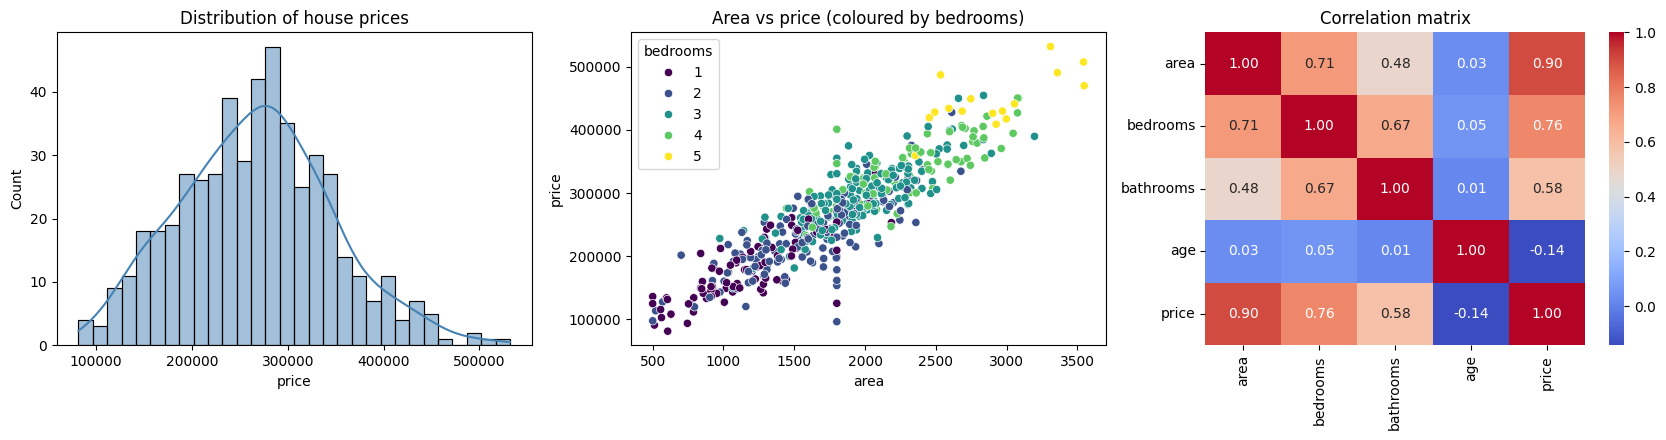

In [77]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

sns.histplot(df["price"], bins=30, kde=True, ax=ax[0], color="steelblue")
ax[0].set_title("Distribution of house prices")

sns.scatterplot(data=df, x="area", y="price", hue="bedrooms", palette="viridis", ax=ax[1])
ax[1].set_title("Area vs price (coloured by bedrooms)")

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=ax[2])
ax[2].set_title("Correlation matrix")

plt.tight_layout()
plt.show()

Conclusions:


1.   Price and area of the house are the strongest correlated factors.
2. Bedrooms are also strongly related to price, but they are correlated with area, so part of their effect is really an area effect.

3.   Age of the house doesn't affect the price of the house as much as other factors


### TASK 2: MODEL TRAINING AND PREDICTION

Splitting the data in X & Y for prediction , then splitting in train and test sets.

In [58]:
features = ["area", "bedrooms", "bathrooms", "age"]
X = df[features]
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Training rows: 400 | Test rows: 100


In [59]:
model = LinearRegression()
model.fit(X_train, y_train)
print("Model trained.")

Model trained.


In [60]:
coef_table = pd.DataFrame({"feature": features, "coefficient": model.coef_})
print(coef_table.to_string(index=False))
print("\nIntercept: %.2f" % model.intercept_)

  feature  coefficient
     area   104.508735
 bedrooms 12412.884706
bathrooms 12696.711247
      age  -933.966266

Intercept: 44228.63


In [61]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:,.0f}")
print(f"RMSE : {rmse:,.0f}")
print(f"R2   : {r2:.3f}")

MAE  : 20,618
RMSE : 26,565
R2   : 0.864


In [64]:
new_house = pd.DataFrame({"area": [1200], "bedrooms": [3], "bathrooms": [2], "age": [10]})
pred = model.predict(new_house)[0]
print(f"Predicted price: {pred:.0f}")
print(f"Typical error range (+/- 1 RMSE): {pred - rmse:.0f} to {pred + rmse:.0f}")

Predicted price: 222932
Typical error range (+/- 1 RMSE): 196367 to 249496


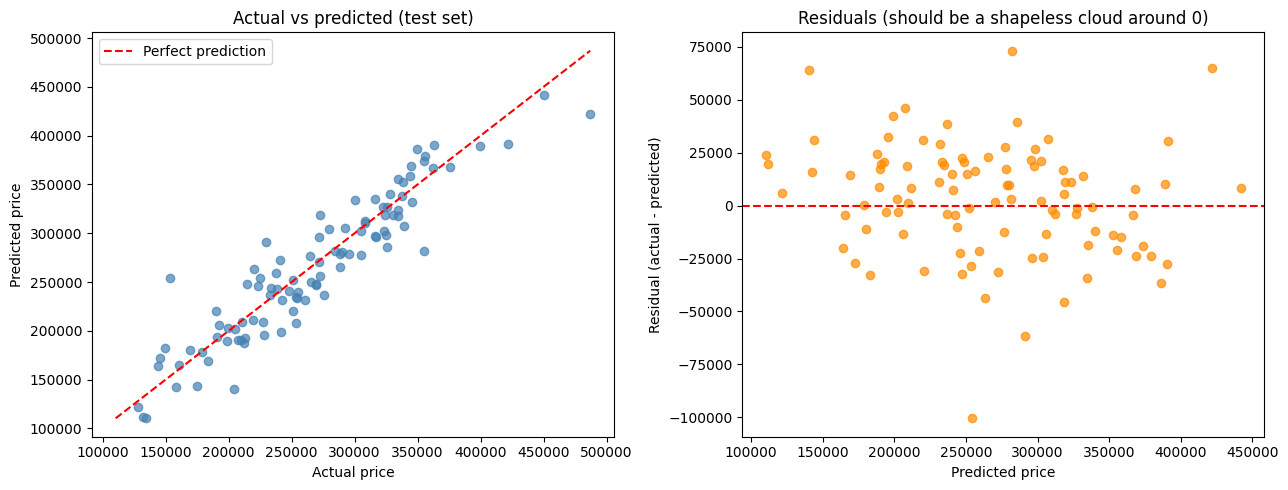

In [65]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].scatter(y_test, y_pred, alpha=0.7, color="steelblue")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax[0].plot(lims, lims, "r--", label="Perfect prediction")
ax[0].set_xlabel("Actual price"); ax[0].set_ylabel("Predicted price")
ax[0].set_title("Actual vs predicted (test set)"); ax[0].legend()

residuals = y_test - y_pred
ax[1].scatter(y_pred, residuals, alpha=0.7, color="darkorange")
ax[1].axhline(0, color="red", linestyle="--")
ax[1].set_xlabel("Predicted price"); ax[1].set_ylabel("Residual (actual - predicted)")
ax[1].set_title("Residuals (should be a shapeless cloud around 0)")

plt.tight_layout(); plt.show()